# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Maya D, Marilyn R, Jiei O

**Date:** 11/9

In [71]:
# Your Phase 1 solution to the problem goes here.
print("Q1")
import numpy as np
import pandas as pd

df = pd.read_csv("data/pierce_county_house_sales.csv")
print(df.isna().sum())
display(df.describe())
df = df.drop_duplicates()
df = df.fillna({"waterfront_type": "None", "view_quality": "None"}) 
df =df.dropna()
df = df[(df["sale_price"] >= 50000) & (df["house_square_feet"] >= 300) &
        (df["bedrooms"].between(1, 10)) & (df["bathrooms"] >= 1)]
df["age"] = (2020 - df["year_built"]).clip(lower=0)  # some houses list year_built 2021 but sold in 2020
df["sale_month"] = pd.to_datetime(df["sale_date"]).dt.month
df = df.drop(columns=["sale_date", "year_built", "interior", "utility_sewer"])
print(df.shape)
df.head()




Q1
sale_date                          0
sale_price                         0
house_square_feet                  0
attic_finished_square_feet         0
basement_square_feet               0
attached_garage_square_feet        0
detached_garage_square_feet        0
fireplaces                         0
hvac_description                   7
exterior                           1
interior                           7
stories                            0
roof_cover                         8
year_built                         0
bedrooms                           0
bathrooms                          0
waterfront_type                16261
view_quality                   15895
utility_sewer                      0
dtype: int64


,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,stories,year_built,bedrooms,bathrooms
count,1.681400e+04,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000
mean,4.612332e+05,1879.941953,24.945878,167.852861,364.425122,38.298501,0.889021,1.558285,1980.469252,3.277983,2.317176
std,2.360833e+05,760.419008,102.066417,429.065832,286.454018,164.691471,0.596731,0.512055,33.339025,0.891240,0.827956
min,2.000000e+03,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1880.000000,0.000000,0.000000
25%,3.480000e+05,1320.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1959.000000,3.000000,2.000000
50%,4.165000e+05,1774.000000,0.000000,0.000000,420.000000,0.000000,1.000000,2.000000,1990.000000,3.000000,2.000000
75%,5.238065e+05,2352.000000,0.000000,0.000000,528.000000,0.000000,1.000000,2.000000,2006.000000,4.000000,3.000000
max,6.130000e+06,9510.000000,1212.000000,4000.000000,2816.000000,3664.000000,5.000000,3.000000,2021.000000,25.000000,8.000000


(16663, 17)


,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,stories,roof_cover,bedrooms,bathrooms,waterfront_type,view_quality,age,sale_month
0,380000,2157,0,0,528,0,0,Warm and Cool Air Zone,Frame Siding,2,Composition Shingle,3,3,None,None,27,1
1,383000,2238,0,0,396,0,0,Forced Air,Frame Siding,2,Composition Shingle,4,3,None,None,3,1
2,419900,1452,0,0,0,0,1,Forced Air,Frame Siding,1,Built Up Rock,3,2,None,None,55,1
3,251660,832,0,0,0,0,0,Forced Air,Frame Vinyl,1,Composition Shingle,2,1,None,None,101,1
4,500000,1780,0,384,484,0,1,Forced Air,Frame Siding,1,Composition Shingle,3,2,None,None,65,1


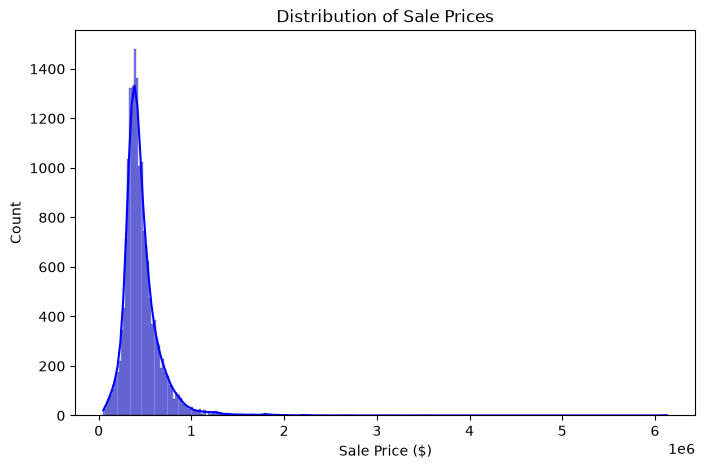

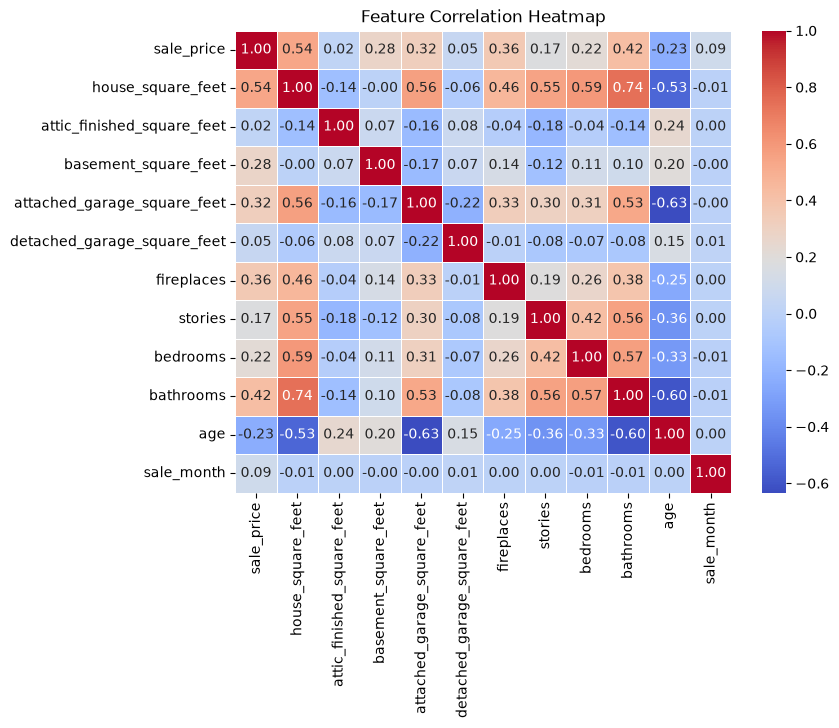

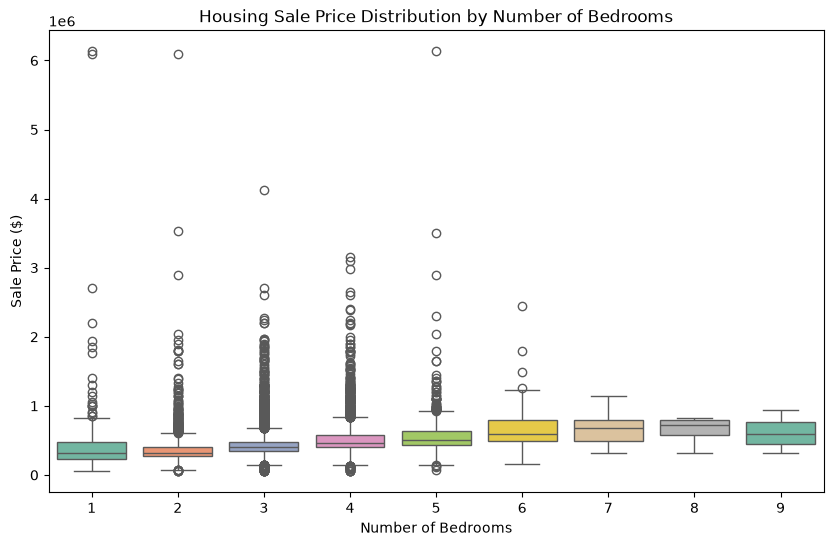

statistics
The mean of the sale price is:  461675.2796615255
The median of the sale price is:  417000.0
The IQR of the sale price is:  174921.0
The 25th percentile of the sale price is:  349000.0
The 75th percentile of the sale price is:  523921.0


In [72]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="sale_price", kde=True, color="blue")
plt.title("Distribution of Sale Prices")
plt.xlabel("Sale Price ($)")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(8, 6))
correlation_matrix = df.corr(numeric_only=True) 
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Feature Correlation Heatmap")
plt.show()

plt.figure(figsize=(10, 6))

# Ensure bedrooms is treated as a category so it groups cleanly on the X-axis
sns.boxplot(data=df, x="bedrooms", y="sale_price", hue="bedrooms", palette="Set2", legend=False)

plt.title("Housing Sale Price Distribution by Number of Bedrooms")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Sale Price ($)")
plt.show()

print("statistics")
print('The mean of the sale price is: ', df['sale_price'].mean())
print('The median of the sale price is: ', df['sale_price'].median())
print('The IQR of the sale price is: ', df['sale_price'].quantile(0.75) - df['sale_price'].quantile(0.25))
print('The 25th percentile of the sale price is: ', df['sale_price'].quantile(0.25))
print('The 75th percentile of the sale price is: ', df['sale_price'].quantile(0.75))


In [73]:
df.info()

<class 'pandas.DataFrame'>
Index: 16663 entries, 0 to 16813
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   sale_price                   16663 non-null  int64
 1   house_square_feet            16663 non-null  int64
 2   attic_finished_square_feet   16663 non-null  int64
 3   basement_square_feet         16663 non-null  int64
 4   attached_garage_square_feet  16663 non-null  int64
 5   detached_garage_square_feet  16663 non-null  int64
 6   fireplaces                   16663 non-null  int64
 7   hvac_description             16663 non-null  str  
 8   exterior                     16663 non-null  str  
 9   stories                      16663 non-null  int64
 10  roof_cover                   16663 non-null  str  
 11  bedrooms                     16663 non-null  int64
 12  bathrooms                    16663 non-null  int64
 13  waterfront_type              16663 non-null  str  
 14  view_q

In [74]:
from sklearn.preprocessing import OneHotEncoder

categorical_columns = df.select_dtypes(include=['object']).columns

encoder = OneHotEncoder(sparse_output=False, drop="first")

encoded_data = encoder.fit_transform(df[categorical_columns])

encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(categorical_columns),
    index=df.index
)

final_df = pd.concat(
    [df.drop(columns=categorical_columns), encoded_df],
    axis=1
)

print("\nOne-Hot Encoded Data:")
print(final_df)

final_df.head()


One-Hot Encoded Data:
       sale_price  house_square_feet  attic_finished_square_feet  \
0          380000               2157                           0   
1          383000               2238                           0   
2          419900               1452                           0   
3          251660                832                           0   
4          500000               1780                           0   
...           ...                ...                         ...   
16808      179519               1632                           0   
16810       96103               1370                           0   
16811      140000                850                         360   
16812      203000               1894                           0   
16813      150000               1040                           0   

       basement_square_feet  attached_garage_square_feet  \
0                         0                          528   
1                         0             

C:\Users\mnros\AppData\Local\Temp\ipykernel_4916\1417965567.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=['object']).columns


,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,stories,bedrooms,bathrooms,...,waterfront_type_WF Salt,waterfront_type_WF Stream/Creek,view_quality_View Avg,view_quality_View Avg +,view_quality_View Good,view_quality_View Good +,view_quality_View Lim,view_quality_View Lim +,view_quality_View Lim -,view_quality_View V-Good
0,380000,2157,0,0,528,0,0,2,3,3,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,383000,2238,0,0,396,0,0,2,4,3,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,419900,1452,0,0,0,0,1,1,3,2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,251660,832,0,0,0,0,0,1,2,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,500000,1780,0,384,484,0,1,1,3,2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [75]:
from sklearn.model_selection import train_test_split

X = final_df.drop(columns = 'sale_price')
Y = final_df['sale_price']

X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

#print( X_train,'\n', X_test)
#print( y_train,'\n', y_test)
print(f"X_train shape: {X_train.shape} | X_test shape: {X_test.shape}")

X_train shape: (13330, 48) | X_test shape: (3333, 48)


In [76]:
print("Q4")
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

numeric = df.select_dtypes(include="number").columns.drop("sale_price")

models = {
    "1: sq ft only": ["house_square_feet"],
    "2: sq ft + rooms": ["house_square_feet", "bedrooms", "bathrooms"],
    "3: all numeric": numeric,
    "4: all features": X_train.columns,
}

for name, cols in models.items():
    lr = LinearRegression().fit(X_train[cols], y_train)
    train_pred = lr.predict(X_train[cols])
    test_pred = lr.predict(X_test[cols])
    print(f"Model {name}")
    print(f"  RMSE  train: {np.sqrt(mean_squared_error(y_train, train_pred)):,.0f}  test: {np.sqrt(mean_squared_error(y_test, test_pred)):,.0f}")
    print(f"  R^2   train: {r2_score(y_train, train_pred):.3f}  test: {r2_score(y_test, test_pred):.3f}")

Q4
Model 1: sq ft only
  RMSE  train: 201,651  test: 166,029
  R^2   train: 0.278  test: 0.360
Model 2: sq ft + rooms
  RMSE  train: 198,782  test: 164,076
  R^2   train: 0.298  test: 0.375
Model 3: all numeric
  RMSE  train: 181,563  test: 143,048
  R^2   train: 0.415  test: 0.525
Model 4: all features
  RMSE  train: 159,097  test: 125,773
  R^2   train: 0.551  test: 0.633


**Q4 answer:** Model 4 (all features) does best, with the lowest test RMSE (about \$126k) and the highest test $R^2$ (about 0.63). Test scores beat train scores because the most expensive sales (\$4M+) all ended up in the training set.

Q5


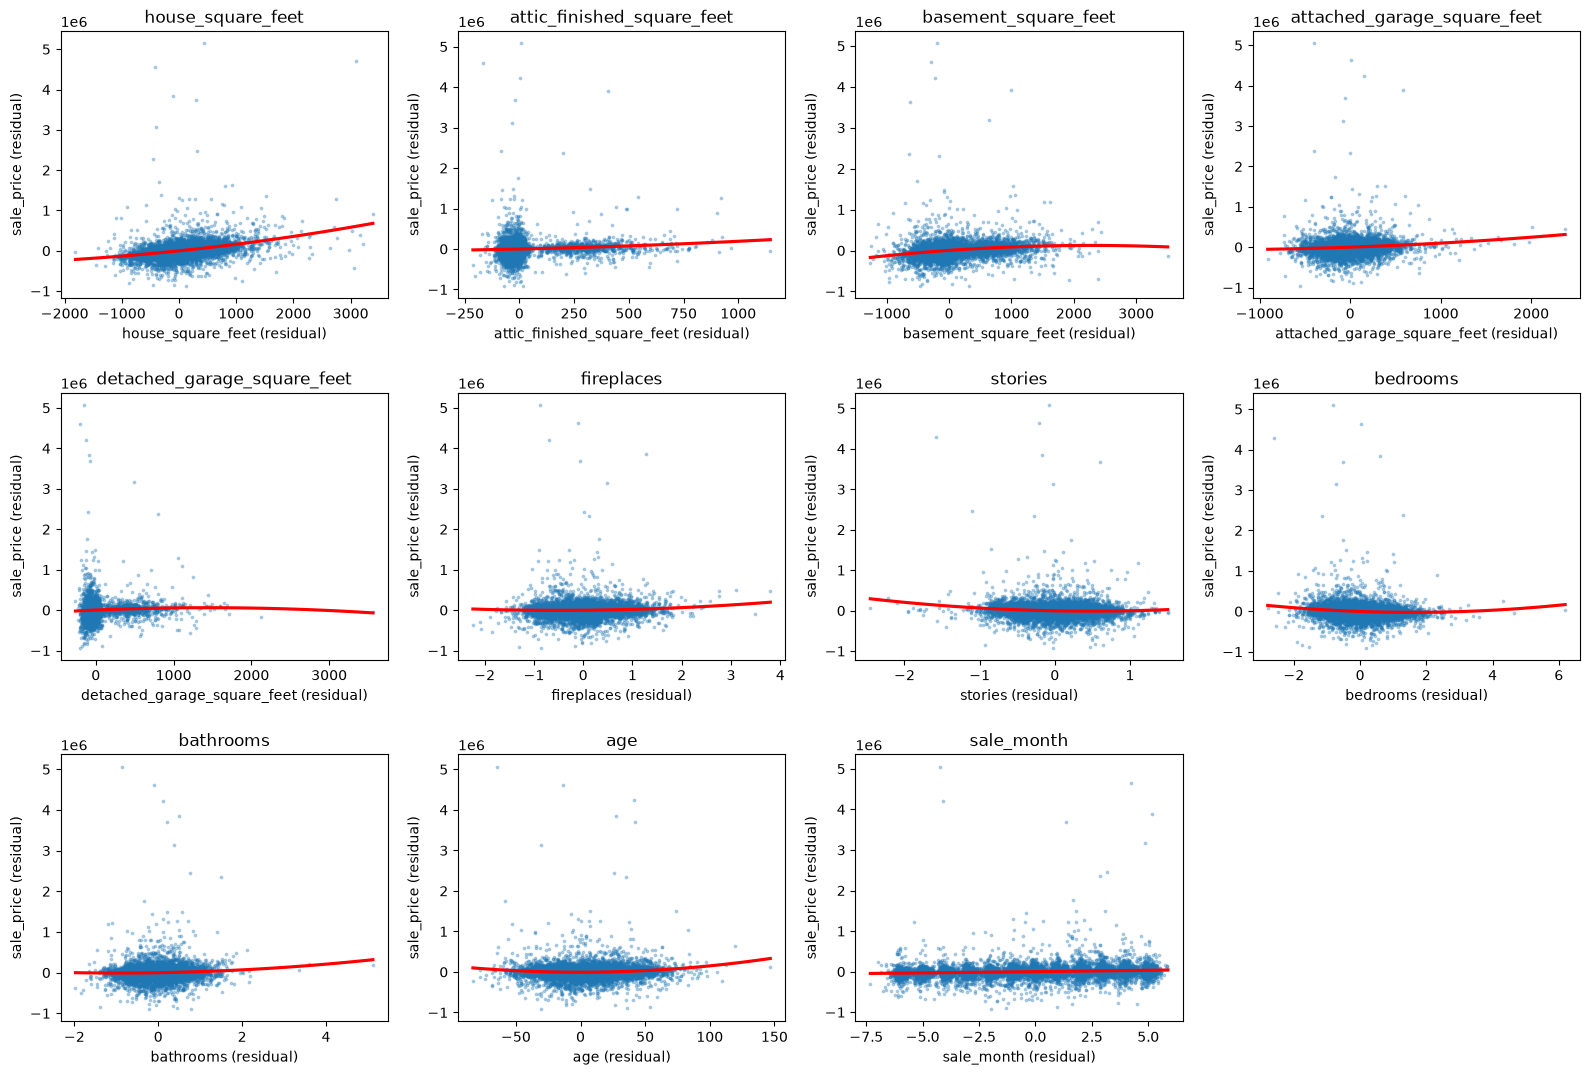

In [77]:
print("Q5")
fig, axes = plt.subplots(3, 4, figsize=(16, 11))

for ax, col in zip(axes.flat, numeric):
    others = X_train.columns.drop(col)
    y_resid = y_train - LinearRegression().fit(X_train[others], y_train).predict(X_train[others])
    x_resid = X_train[col] - LinearRegression().fit(X_train[others], X_train[col]).predict(X_train[others])
    sns.regplot(x=x_resid, y=y_resid, ax=ax, order=2, ci=None,
                scatter_kws={"s": 3, "alpha": 0.3}, line_kws={"color": "red"})
    ax.set_title(col)
    ax.set_xlabel(f"{col} (residual)")
    ax.set_ylabel("sale_price (residual)")

axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

**Q5 answer:** Yes. `house_square_feet` curves upward and `age` is U-shaped. The other variables look roughly linear.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [78]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]